In [1]:
from pyspark.sql import SparkSession

In [2]:
spark = SparkSession.builder \
    .appName("DPA-Part1") \
    .config("spark.driver.memory", "6g") \
    .config("spark.sql.shuffle.partitions", "50") \
    .getOrCreate()


## 1. Ingestion

In [3]:
import glob

dump_dirs = sorted(glob.glob("../data/raw/mb/listenbrainz-spark-dump-*/"))
temp = spark.read.parquet(*dump_dirs)
temp.printSchema()


root
 |-- listened_at: timestamp (nullable = true)
 |-- created: timestamp (nullable = true)
 |-- user_id: long (nullable = true)
 |-- recording_msid: string (nullable = true)
 |-- artist_name: string (nullable = true)
 |-- artist_credit_id: long (nullable = true)
 |-- release_name: string (nullable = true)
 |-- release_mbid: string (nullable = true)
 |-- recording_name: string (nullable = true)
 |-- recording_mbid: string (nullable = true)
 |-- artist_credit_mbids: array (nullable = true)
 |    |-- element: string (containsNull = true)



In [5]:
from pyspark.sql.types import *

lb_schema = StructType([
    StructField("listened_at", TimestampType()),
    StructField("created", TimestampType()),
    StructField("user_id", LongType()),
    StructField("recording_msid", StringType()),
    StructField("artist_name", StringType()),
    StructField("artist_credit_id", LongType()),
    StructField("release_name", StringType()),
    StructField("release_mbid", StringType()),
    StructField("recording_name", StringType()),
    StructField("recording_mbid", StringType()),
    StructField("artist_credit_mbids", ArrayType(StringType())),
])

listens = spark.read.schema(lb_schema).parquet(
    *[d + "*.parquet" for d in dump_dirs]
)

print("Total listens:", listens.count())


Total listens: 39431528


In [6]:
artist_schema = StructType([
    StructField("id", IntegerType()),
    StructField("gid", StringType()),
    StructField("name", StringType()),
    StructField("sort_name", StringType()),
    StructField("begin_date_year", IntegerType()),
    StructField("begin_date_month", IntegerType()),
    StructField("begin_date_day", IntegerType()),
    StructField("end_date_year", IntegerType()),
    StructField("end_date_month", IntegerType()),
    StructField("end_date_day", IntegerType()),
    StructField("type", IntegerType()),
    StructField("area", IntegerType()),
    StructField("gender", IntegerType()),
    StructField("comment", StringType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("ended", StringType()),
    StructField("begin_area", IntegerType()),
    StructField("end_area", IntegerType()),
])

artist = spark.read.schema(artist_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/artist")

print("Total artists:", artist.count())


Total artists: 3015712


In [7]:
area_schema = StructType([
    StructField("id", IntegerType()),
    StructField("gid", StringType()),
    StructField("name", StringType()),
    StructField("type", IntegerType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("begin_date_year", IntegerType()),
    StructField("begin_date_month", IntegerType()),
    StructField("begin_date_day", IntegerType()),
    StructField("end_date_year", IntegerType()),
    StructField("end_date_month", IntegerType()),
    StructField("end_date_day", IntegerType()),
    StructField("ended", StringType()),
    StructField("comment", StringType()),
])

area = spark.read.schema(area_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/area")

print("Total areas:", area.count())


Total areas: 120108


## 2. Cleaning

In [8]:
from pyspark.sql.functions import col, size

listens_clean = listens \
    .filter(col("artist_credit_mbids").isNotNull() & (size("artist_credit_mbids") > 0)) \
    .select("listened_at", "user_id", "artist_credit_id", "artist_name", "recording_mbid", "artist_credit_mbids")



artist_clean = artist.dropna(subset=["area"]) \
    .select("id", "gid", "name", "area")

area_clean = area.select("id", "name", "type")

print("listens_clean:", listens_clean.count())
print("artist_clean:", artist_clean.count())
print("area_clean:", area_clean.count())


listens_clean: 32114649
artist_clean: 1497472
area_clean: 120108


In [9]:
listens_clean.write.mode("overwrite").parquet("../data/processed/listens_clean")
artist_clean.write.mode("overwrite").parquet("../data/processed/artist_clean")
area_clean.write.mode("overwrite").parquet("../data/processed/area_clean")

print("Cleaned tables written.")


Cleaned tables written.


## 3. Spark SQL Analysis

In [15]:
listens_clean = spark.read.parquet("../data/processed/listens_clean")
artist_clean  = spark.read.parquet("../data/processed/artist_clean")
area_clean    = spark.read.parquet("../data/processed/area_clean")

listens_clean.createOrReplaceTempView("listens")
artist_clean.createOrReplaceTempView("artist")
area_clean.createOrReplaceTempView("area")


### Main join
Link listens to artist origin country (`area.type = 1` keeps countries only).


In [16]:
from pyspark.sql.functions import explode, col

joined = listens_clean \
    .filter(col("artist_credit_mbids").isNotNull()) \
    .select("user_id", explode("artist_credit_mbids").alias("artist_mbid")) \
    .join(artist_clean, artist_clean["gid"] == col("artist_mbid")) \
    .join(area_clean.filter(col("type") == 1), artist_clean["area"] == area_clean["id"]) \
    .select("user_id", artist_clean["gid"], artist_clean["name"].alias("artist_name"), area_clean["name"].alias("country"))

joined.createOrReplaceTempView("joined")
print("Joined rows:", joined.count())
joined.show(5)


Joined rows: 30217773
+-------+--------------------+-----------+-------+
|user_id|                 gid|artist_name|country|
+-------+--------------------+-----------+-------+
| 116321|00034ede-a1f1-421...|    O Rappa| Brazil|
| 116321|00034ede-a1f1-421...|    O Rappa| Brazil|
| 121966|00034ede-a1f1-421...|    O Rappa| Brazil|
|  45898|00034ede-a1f1-421...|    O Rappa| Brazil|
|  45898|00034ede-a1f1-421...|    O Rappa| Brazil|
+-------+--------------------+-----------+-------+
only showing top 5 rows



In [17]:
import shutil
from pyspark.sql.functions import explode, col

spark.catalog.clearCache()
shutil.rmtree("../data/processed/joined", ignore_errors=True)

listens_clean = spark.read.parquet("../data/processed/listens_clean")
artist_clean  = spark.read.parquet("../data/processed/artist_clean")
area_clean    = spark.read.parquet("../data/processed/area_clean")

joined = listens_clean \
    .filter(col("artist_credit_mbids").isNotNull()) \
    .select("user_id", explode("artist_credit_mbids").alias("artist_mbid")) \
    .join(artist_clean, artist_clean["gid"] == col("artist_mbid")) \
    .join(area_clean.filter(col("type") == 1), artist_clean["area"] == area_clean["id"]) \
    .select("user_id", artist_clean["gid"], artist_clean["name"].alias("artist_name"), area_clean["name"].alias("country"))

joined.write.mode("overwrite").parquet("../data/processed/joined")
joined = spark.read.parquet("../data/processed/joined")
joined.createOrReplaceTempView("joined")
print("done")


done


## 4. Analysis

### Top 20 artists by total listen count

In [18]:
spark.sql("""
    SELECT artist_name, country, COUNT(*) AS total_listens
    FROM joined
    GROUP BY artist_name, country
    ORDER BY total_listens DESC
    LIMIT 20
""").show(20, truncate=False)


+--------------+--------------+-------------+
|artist_name   |country       |total_listens|
+--------------+--------------+-------------+
|BTS           |South Korea   |2423277      |
|Agust D       |South Korea   |186272       |
|Jimin         |South Korea   |171722       |
|Jung Kook     |South Korea   |138216       |
|Radiohead     |United Kingdom|117241       |
|Die drei ???  |Germany       |115644       |
|Linkin Park   |United States |114218       |
|RM            |South Korea   |109325       |
|The Beatles   |United Kingdom|109036       |
|j‐hope        |South Korea   |103378       |
|Ye            |United States |99485        |
|Kendrick Lamar|United States |94373        |
|Taylor Swift  |United States |94274        |
|Eminem        |United States |82655        |
|Jin           |South Korea   |82047        |
|V             |South Korea   |81152        |
|Bladee        |Sweden        |71143        |
|C418          |Germany       |69764        |
|Drake         |Canada        |601

### Top 10 countries by total listens

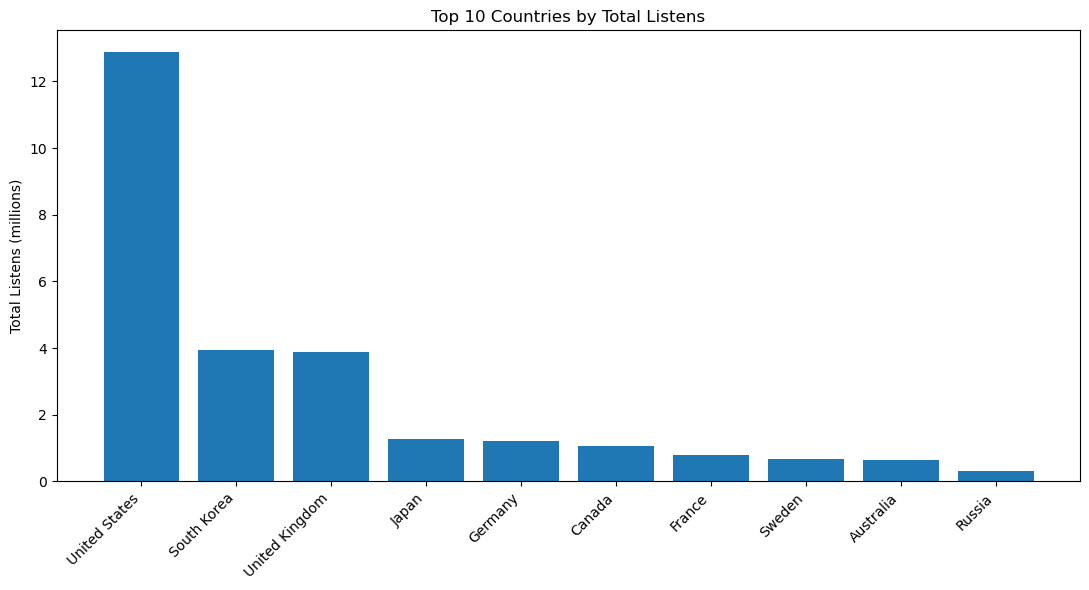

In [19]:
import matplotlib.pyplot as plt

top_countries_pd = spark.sql("""
    SELECT country, COUNT(*) AS total_listens
    FROM joined
    GROUP BY country
    ORDER BY total_listens DESC
    LIMIT 10
""").toPandas()

plt.figure(figsize=(11, 6))
plt.bar(top_countries_pd["country"], top_countries_pd["total_listens"] / 1_000_000)
plt.xticks(rotation=45, ha="right")
plt.title("Top 10 Countries by Total Listens")
plt.ylabel("Total Listens (millions)")
plt.tight_layout()
plt.show()


### Listens per day (Oct 2026)

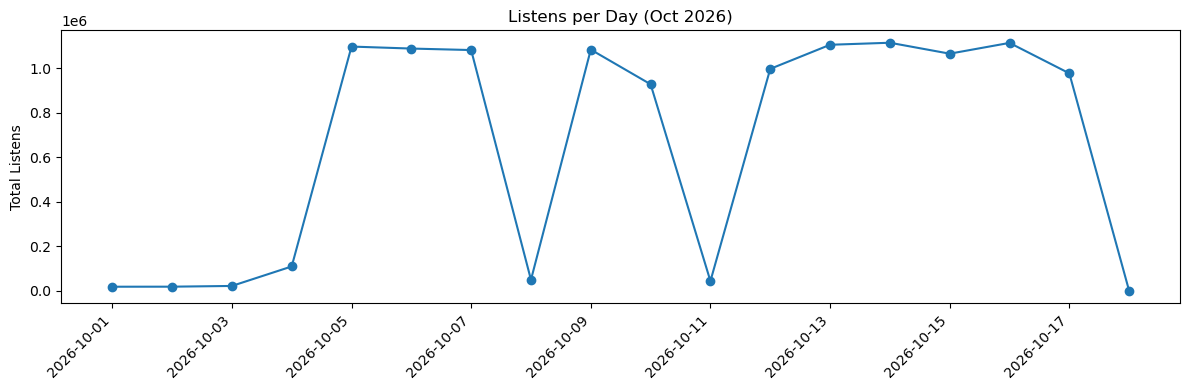

In [20]:
listens_per_day_pd = spark.sql("""
    SELECT DATE(listened_at) AS day, COUNT(*) AS total_listens
    FROM listens
    WHERE listened_at >= '2026-10-01'
    GROUP BY day
    ORDER BY day
""").toPandas()

plt.figure(figsize=(12, 4))
plt.plot(listens_per_day_pd["day"], listens_per_day_pd["total_listens"], marker="o")
plt.xticks(rotation=45, ha="right")
plt.title("Listens per Day (Oct 2026)")
plt.ylabel("Total Listens")
plt.tight_layout()
plt.show()

### User activity distribution


In [22]:
spark.sql("""
    SELECT
        COUNT(*) AS total_users,
        ROUND(AVG(listen_count), 2) AS avg_listens,
        MAX(listen_count) AS max_listens,
        MIN(listen_count) AS min_listens,
        PERCENTILE(listen_count, 0.5) AS median_listens,
        PERCENTILE(listen_count, 0.9) AS p90_listens
    FROM (
        SELECT user_id, COUNT(*) AS listen_count
        FROM listens
        GROUP BY user_id
    )
""").show(truncate=False)


+-----------+-----------+-----------+-----------+--------------+-----------------+
|total_users|avg_listens|max_listens|min_listens|median_listens|p90_listens      |
+-----------+-----------+-----------+-----------+--------------+-----------------+
|38134      |842.15     |428100     |1          |129.0         |682.7000000000044|
+-----------+-----------+-----------+-----------+--------------+-----------------+



### User listening diversity
How many distinct artist origin countries does each user listen to?


In [25]:
user_country_diversity = spark.sql("""
    SELECT
        user_id,
        COUNT(DISTINCT country) AS distinct_countries_listened,
        COUNT(DISTINCT gid)     AS distinct_artists_listened
    FROM joined
    GROUP BY user_id
    ORDER BY distinct_countries_listened DESC
""")

user_country_diversity.createOrReplaceTempView("user_diversity")
user_country_diversity.show(20, truncate=False)


+-------+---------------------------+-------------------------+
|user_id|distinct_countries_listened|distinct_artists_listened|
+-------+---------------------------+-------------------------+
|208717 |119                        |7653                     |
|214795 |107                        |10345                    |
|201952 |107                        |10633                    |
|210446 |106                        |3877                     |
|179122 |105                        |8077                     |
|216199 |105                        |8927                     |
|215368 |104                        |4876                     |
|206743 |100                        |4716                     |
|210109 |99                         |3777                     |
|183798 |97                         |7078                     |
|210231 |95                         |7654                     |
|206491 |94                         |7231                     |
|216345 |94                         |570

### Diversity summary statistics
Mean, median, p90, and max distinct countries per user.

In [26]:
spark.sql("""
    SELECT
        COUNT(DISTINCT user_id)                        AS total_users,
        ROUND(AVG(distinct_countries_listened), 2)     AS mean_countries,
        PERCENTILE(distinct_countries_listened, 0.5)   AS median_countries,
        PERCENTILE(distinct_countries_listened, 0.9)   AS p90_countries,
        MAX(distinct_countries_listened)               AS max_countries,
        MIN(distinct_countries_listened)               AS min_countries
    FROM user_diversity
""").show(truncate=False)


+-----------+--------------+----------------+-------------+-------------+-------------+
|total_users|mean_countries|median_countries|p90_countries|max_countries|min_countries|
+-----------+--------------+----------------+-------------+-------------+-------------+
|37740      |9.22          |7.0             |18.0         |119          |1            |
+-----------+--------------+----------------+-------------+-------------+-------------+



BTS listener check:

In [28]:
spark.sql("""
    SELECT artist_name, country,
           COUNT(DISTINCT user_id) AS listeners,
           COUNT(*) AS total_listens,
           ROUND(COUNT(*) / COUNT(DISTINCT user_id), 1) AS listens_per_listener
    FROM joined
    WHERE artist_name = 'BTS'
    GROUP BY artist_name, country
""").show(truncate=False)


+-----------+-----------+---------+-------------+--------------------+
|artist_name|country    |listeners|total_listens|listens_per_listener|
+-----------+-----------+---------+-------------+--------------------+
|BTS        |South Korea|1589     |2423277      |1525.0              |
+-----------+-----------+---------+-------------+--------------------+



foreign share per artist:

In [29]:
spark.sql("""
    SELECT artist_name, country,
           COUNT(DISTINCT user_id) AS listeners
    FROM joined
    GROUP BY artist_name, country
    ORDER BY listeners DESC
    LIMIT 20
""").show(truncate=False)


+---------------------+--------------+---------+
|artist_name          |country       |listeners|
+---------------------+--------------+---------+
|Linkin Park          |United States |5244     |
|Radiohead            |United Kingdom|4671     |
|Daft Punk            |France        |3870     |
|Tame Impala          |Australia     |3797     |
|Coldplay             |United Kingdom|3692     |
|Kendrick Lamar       |United States |3690     |
|The Weeknd           |Canada        |3610     |
|Green Day            |United States |3361     |
|Eminem               |United States |3303     |
|Ye                   |United States |3287     |
|Michael Jackson      |United States |3271     |
|Nirvana              |United States |3246     |
|Lady Gaga            |United States |3169     |
|Red Hot Chili Peppers|United States |3166     |
|Arctic Monkeys       |United Kingdom|3094     |
|Taylor Swift         |United States |3091     |
|Queen                |United Kingdom|3074     |
|System of a Down   

### Correlation between artist diversity and geographic diversity
Pearson r between distinct artists listened and distinct countries listened per user.

In [30]:
from pyspark.sql.functions import corr

user_country_diversity.select(
    corr("distinct_artists_listened", "distinct_countries_listened").alias("correlation")
).show()


+------------------+
|       correlation|
+------------------+
|0.6881782511320547|
+------------------+



### Bridge artist analysis
Artists listened to from the most distinct countries.

> **Note**: This query returns 0 results because `artist_credit_id = artist.id` maps every credit to exactly one origin country. Bridge behaviour cannot be measured by origin country alone and will be addressed in Part 3 using the collaboration graph (`l_artist_artist`).

In [31]:
bridge = spark.sql("""
    SELECT gid, artist_name, COUNT(DISTINCT country) AS country_reach
    FROM joined
    GROUP BY gid, artist_name
    HAVING country_reach > 1
    ORDER BY country_reach DESC
    LIMIT 20
""")

print("Bridge artists found:", bridge.count())
bridge.show(20, truncate=False)


Bridge artists found: 0
+---+-----------+-------------+
|gid|artist_name|country_reach|
+---+-----------+-------------+
+---+-----------+-------------+



## 5. Load artist-to-artist relationships (for Part 3)

In [32]:
from pyspark.sql.types import *

l_artist_schema = StructType([
    StructField("id", IntegerType()),
    StructField("link", IntegerType()),
    StructField("entity0", IntegerType()),
    StructField("entity1", IntegerType()),
    StructField("entity0_credit", StringType()),
    StructField("entity1_credit", StringType()),
    StructField("edits_pending", IntegerType()),
    StructField("last_updated", StringType()),
    StructField("link_order", IntegerType()),
    StructField("entity0_cardinality", IntegerType()),
    StructField("entity1_cardinality", IntegerType()),
])

l_artist_artist = spark.read.schema(l_artist_schema) \
    .option("sep", "\t") \
    .option("nullValue", "\\N") \
    .csv("../data/raw/mb/mbdump/l_artist_artist")

print("Total relations:", l_artist_artist.count())
l_artist_artist.createOrReplaceTempView("l_artist_artist")


Total relations: 865360
